In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from torch.optim.lr_scheduler import ReduceLROnPlateau


In [2]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(-2, 2, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.zeros(n_basis, n_basis, requires_grad=True)
        
        
        
        ################Changes#################
        self.raw_k = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]


        return y
    
    def k(self):
        return self.softplus(self.raw_k)
    
   


In [3]:
torch.manual_seed(42)

# model = bsplines2D(10,3)
# If We dont get good fit, train the BC for 20,3 and use here 20,3
# model = bsplines2D(20,2)
model = bsplines2D(20,3)

In [4]:
nn.Softplus(model.raw_k)

Softplus(
  beta=Parameter containing:
  tensor([0.1000], requires_grad=True), threshold=20.0
)

In [5]:
a1=1
a2=1
k=1

In [6]:
colloc_points = 5000

# Reproducable input points
torch.manual_seed(42)

#X[:,0] is x and X[:,1] is time
#########Change###########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)*4-2
#########Change###########
u_exact = torch.sin(a1*torch.pi * X[:,0]) * torch.sin(a2*torch.pi * X[:,1])
# u_exact = torch.sin(2*torch.pi * X[:,0]) * torch.exp(-torch.pi**2 *0.03* X[:,1]*4)
noise = noise = torch.normal(mean=0.0, std=0.05, size=u_exact.shape)
u_noisy = u_exact + noise
#########Change###########
X.requires_grad_(True)

tensor([[ 1.5291,  1.6600],
        [-0.4685,  1.8372],
        [-0.4382,  0.4036],
        ...,
        [ 1.7111,  0.3174],
        [ 1.3233, -1.1276],
        [ 1.6479, -0.3556]], requires_grad=True)

In [7]:
# epochs = 6000
epochs = 20000

###########Changes#################
learning_rate=1e-3
# learning_rate=1e-4
###########Changes#################

# Right-hand side of Poisson equation
def f(x, y,k):
    return (k**2-(a1**2+a2**2)*np.pi ** 2) * torch.sin(a1*np.pi * x) * torch.sin(a2*np.pi * y)


###########Changes#################
optimizer = torch.optim.Adam([model.coeffs, model.raw_k], lr=learning_rate)
###########Changes#################
loss_vec = []

for epoch in range(epochs):

    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    

    ###########Changes#################
    k = model.k()
    source = f(X[:,0], X[:,1], k)
    # Residual loss
    res = u_xx + u_yy +k**2*u - source
     
    
    loss_pde = torch.mean(res**2)
    
    loss_data = torch.mean((u - u_exact)**2) 

    loss = loss_pde + loss_data
    ###########Changes#################



    loss.backward()
    ###########Changes#################
    optimizer.step()
    ###########Changes#################
    # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs_trainable -= learning_rate * model.coeffs_trainable.grad
    # # Zero the gradients after each update
    # model.coeffs_trainable.grad.zero_()
    # x.grad.zero_()
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        k_est = k.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {k_est:.5f}")

Epoch     4 | Loss: 9.4742e+01 | D: 0.74650
Epoch     9 | Loss: 9.3414e+01 | D: 0.74913
Epoch    14 | Loss: 9.2136e+01 | D: 0.75176
Epoch    19 | Loss: 9.0895e+01 | D: 0.75440
Epoch    24 | Loss: 8.9686e+01 | D: 0.75704
Epoch    29 | Loss: 8.8507e+01 | D: 0.75967
Epoch    34 | Loss: 8.7355e+01 | D: 0.76230
Epoch    39 | Loss: 8.6228e+01 | D: 0.76493
Epoch    44 | Loss: 8.5125e+01 | D: 0.76756
Epoch    49 | Loss: 8.4042e+01 | D: 0.77019
Epoch    54 | Loss: 8.2981e+01 | D: 0.77281
Epoch    59 | Loss: 8.1938e+01 | D: 0.77543
Epoch    64 | Loss: 8.0913e+01 | D: 0.77805
Epoch    69 | Loss: 7.9905e+01 | D: 0.78066
Epoch    74 | Loss: 7.8914e+01 | D: 0.78327
Epoch    79 | Loss: 7.7937e+01 | D: 0.78588
Epoch    84 | Loss: 7.6976e+01 | D: 0.78848
Epoch    89 | Loss: 7.6028e+01 | D: 0.79108
Epoch    94 | Loss: 7.5094e+01 | D: 0.79367
Epoch    99 | Loss: 7.4173e+01 | D: 0.79626
Epoch   104 | Loss: 7.3265e+01 | D: 0.79885
Epoch   109 | Loss: 7.2369e+01 | D: 0.80143
Epoch   114 | Loss: 7.1484e+01 |

KeyboardInterrupt: 

In [9]:
print(model.k().item())

1.1822682619094849


In [9]:
#Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/diffusion_inverse/bsplines_loss_noise.npy', loss_vec_npy )

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable, 'D_trainable': model.raw_D }
torch.save(params, './results/diffusion_inverse/model_bsplines_noise.pth')

In [22]:
# Load model trainable parameters
model_s = bsplines2D(20,3)
loaded_params = torch.load('./results/diffusion_inverse/model_bsplines.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']
model_s.raw_D = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_48404\3282493418.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/diffusion_inverse/

In [27]:
# Load loss
loss_bsplines_s = np.load('./results/diffusion_inverse/bsplines_loss.npy')

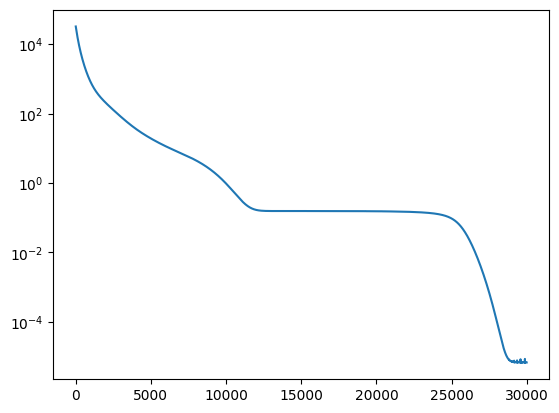

In [28]:
plt.plot(loss_bsplines_s)
plt.yscale('log')

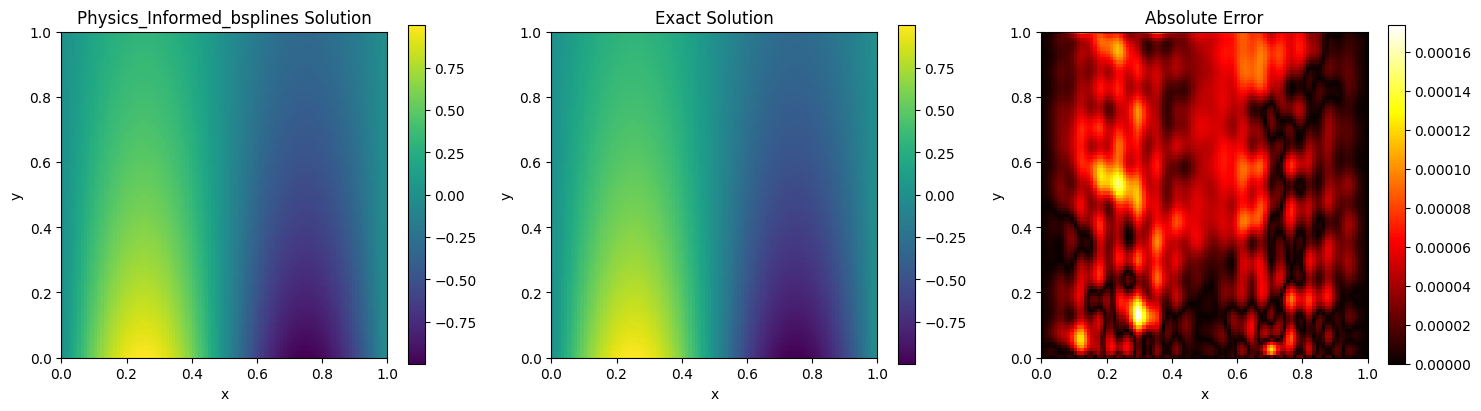

In [26]:
# 🔍 Evaluate on a grid
x = y = np.linspace(-2, 2, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Tg*4)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

PINN solution

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Set device and seed
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

# True parameter
D_true = 0.03

# Synthetic solution: u(x,t) = sin(2πx) * exp(-4π² D t)
def analytical_solution(x, t, D):
    return torch.sin(2 * np.pi * x) * torch.exp(-4 * np.pi**2 * D * t)

# Neural network model
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 1)
        )
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

    def D(self):
        return self.softplus(self.raw_D)  # ensures positivity

# PDE residual
def pde_residual(model, x, t):
    x.requires_grad_(True)
    t.requires_grad_(True)
    u = model(x, t)
    D = model.D()

    u_t = torch.autograd.grad(u, t, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u), create_graph=True)[0]

    f = u_t - D * u_xx
    return f

# Sample data
N_data = 100
N_colloc = 5000


x_colloc = torch.rand(N_colloc, 1, device=device)
t_colloc = torch.rand(N_colloc, 1, device=device)
# x_data = torch.rand(N_data, 1, device=device)
# t_data = torch.rand(N_data, 1, device=device)
u_data = analytical_solution(x_colloc, t_colloc, D_true)

# Add noise
noise = torch.normal(mean=0.0, std=0.05, size=u_data.shape, device=device)
u_noisy = u_data + noise


# Initialize model
model = PINN().to(device)


In [2]:
noise

tensor([[-0.0259],
        [ 0.0613],
        [ 0.0313],
        ...,
        [ 0.0668],
        [ 0.0354],
        [ 0.0194]], device='cuda:0')

In [4]:
# Training loop
# First 10000 1e-3 and then 1e-4

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.8, patience=10, min_lr=1e-5)

loss_history = []
for epoch in range(10000):
    optimizer.zero_grad()
    
    ##### Changes ####### 
    u_pred = model(x_colloc, t_colloc)
    ##### Changes ####### 

    loss_data = torch.mean((u_pred - u_noisy)**2)
    
    f = pde_residual(model, x_colloc, t_colloc)
    loss_pde = torch.mean(f**2)
    
    loss = loss_data + loss_pde
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if epoch % 500 == 0:
        D_est = model.D().item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {D_est:.5f}")
        

# Final estimated D
print(f"\nEstimated D: {model.D().item():.5f} (True D: {D_true})")

Epoch     0 | Loss: 2.6169e-03 | D: 0.03026
Epoch   500 | Loss: 2.4597e-03 | D: 0.03030
Epoch  1000 | Loss: 2.4724e-03 | D: 0.03030
Epoch  1500 | Loss: 2.4583e-03 | D: 0.03030
Epoch  2000 | Loss: 2.4580e-03 | D: 0.03030
Epoch  2500 | Loss: 2.4576e-03 | D: 0.03030
Epoch  3000 | Loss: 2.4575e-03 | D: 0.03030
Epoch  3500 | Loss: 2.4647e-03 | D: 0.03030
Epoch  4000 | Loss: 2.4577e-03 | D: 0.03030
Epoch  4500 | Loss: 2.4621e-03 | D: 0.03029
Epoch  5000 | Loss: 2.4581e-03 | D: 0.03029
Epoch  5500 | Loss: 2.4577e-03 | D: 0.03029
Epoch  6000 | Loss: 2.4568e-03 | D: 0.03029
Epoch  6500 | Loss: 2.4574e-03 | D: 0.03029
Epoch  7000 | Loss: 2.4575e-03 | D: 0.03029
Epoch  7500 | Loss: 2.4567e-03 | D: 0.03029
Epoch  8000 | Loss: 2.4620e-03 | D: 0.03029
Epoch  8500 | Loss: 2.4569e-03 | D: 0.03029
Epoch  9000 | Loss: 2.4577e-03 | D: 0.03029
Epoch  9500 | Loss: 2.4565e-03 | D: 0.03029

Estimated D: 0.03029 (True D: 0.03)


In [23]:
#Save loss
loss_vec_npy = np.array(loss_history)
np.save('./results/diffusion_inverse/pinn_loss.npy', loss_vec_npy )

#Save model trainable parameters
torch.save(model.state_dict(), './results/diffusion_inverse/model_pinn.pth')

In [7]:
#Save loss
loss_vec_npy = np.array(loss_history)
np.save('./results/diffusion_inverse/pinn_loss_noisy.npy', loss_vec_npy )

#Save model trainable parameters
torch.save(model.state_dict(), './results/diffusion_inverse/model_pinn_noisy.pth')

In [9]:
model_s = PINN()


In [10]:
model_s.load_state_dict(torch.load('./results/diffusion_inverse/model_pinn_noisy.pth'))


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_52344\1890809348.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_s.load_state_dict(torch.load('./results/diffusion_

<All keys matched successfully>

In [12]:
print(model_s.D().item())


0.030291007831692696
